# 04. Gaussian mixtures and EM

## Business use

Segments on orders per year and average order value, product groupings, and low-density orders that look unusual. A customer can be 84% one segment and 16% another. Personalisation and pricing rules need that softness. k-means cannot express it: k-means is the hard-assignment, equal-spherical-variance limit of a Gaussian mixture.

## Intuition

Each customer comes from one of $K$ hidden groups. Each group is a Gaussian cloud. If we knew the labels, fitting would be a mean and a variance per group. If we knew the groups, assigning points would be trivial. EM alternates the two with soft assignments, and the likelihood cannot go down.

A Bayesian mixture puts priors on the weights and centroids and returns a posterior. EM returns one maximum. Same latent-variable model, different inference. EM is the nightly retrain. The Bayesian fit is what we use when a segment is small and the decision needs an interval.

## Math

$$
p(x) = \sum_{k=1}^{K} \pi_k \, \mathcal{N}(x \mid \mu_k, \Sigma_k), \quad \sum_k \pi_k = 1
$$

E-step, responsibility that point $i$ came from component $k$:

$$
\gamma_{ik} = \frac{\pi_k \, \mathcal{N}(x_i \mid \mu_k, \sigma_k^2)}{\sum_j \pi_j \, \mathcal{N}(x_i \mid \mu_j, \sigma_j^2)}
$$

M-step, responsibility-weighted maximum likelihood:

$$
N_k = \sum_i \gamma_{ik}, \quad
\pi_k = N_k / n, \quad
\mu_k = \sum_i \gamma_{ik} x_i / N_k, \quad
\sigma_k^2 = \sum_i \gamma_{ik} (x_i - \mu_k)^2 / N_k
$$

The E-step makes a lower bound touch the log-likelihood. The M-step raises the bound. A decrease in the log-likelihood is a bug. EM finds local optima, so restart, and floor the variance so a component cannot collapse onto one point.

$$
\mathrm{BIC} = p \ln n - 2 \ln \hat L, \quad \mathrm{AIC} = 2p - 2 \ln \hat L
$$

Lower is better. BIC's penalty grows with $\ln n$.


## Step 1. EM for a 1D mixture of basket sizes

Five thousand orders. Log basket value comes from three shopper types. Truth: weights 0.50 / 0.35 / 0.15, means 3.0 / 4.0 / 5.2, standard deviations 0.35 / 0.30 / 0.40. Initialise with equal weights, means drawn from the data, and the overall standard deviation.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from scipy.stats import norm
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(11)
true_w = np.array([0.50, 0.35, 0.15])
true_mu = np.array([3.0, 4.0, 5.2])
true_sd = np.array([0.35, 0.30, 0.40])
component = rng.choice(3, 5000, p=true_w)
basket = rng.normal(true_mu[component], true_sd[component])
print("orders:", basket.size, "mean log basket:", round(float(basket.mean()), 3))


def em_gmm_1d(x: np.ndarray, n_components: int, n_iter: int = 500, tol: float = 1e-6, seed: int = 0):
    random = np.random.default_rng(seed)
    weight = np.full(n_components, 1 / n_components)
    mean = random.choice(x, n_components, replace=False)
    sd = np.full(n_components, x.std())
    history = []
    gamma = np.zeros((len(x), n_components))
    for iteration in range(n_iter):
        log_prob = np.log(weight) + norm.logpdf(x[:, None], mean, sd)
        log_marginal = np.logaddexp.reduce(log_prob, axis=1)
        gamma = np.exp(log_prob - log_marginal[:, None])
        history.append(float(log_marginal.sum()))
        counts = gamma.sum(0)
        weight = counts / len(x)
        mean = (gamma * x[:, None]).sum(0) / counts
        sd = np.sqrt((gamma * (x[:, None] - mean) ** 2).sum(0) / counts) + 1e-6
        if iteration > 0 and history[-1] - history[-2] < tol:
            break
    return weight, mean, sd, gamma, np.array(history)


weight, mean, sd, gamma, history = em_gmm_1d(basket, 3)
order = np.argsort(mean)
print("iterations:", len(history), "monotonic increase:", bool(np.all(np.diff(history) >= -1e-8)))
marks = [0, 1, 4, 9, 19, len(history) - 1]
print("log-lik at iters 1,2,5,10,20,last:", [round(float(history[i]), 1) for i in marks])
print("weights:", np.round(weight[order], 3))
print("means:", np.round(mean[order], 3), " truth:", true_mu)
print("sds:", np.round(sd[order], 3), " truth:", true_sd)
assert np.all(np.diff(history) >= -1e-8)

orders: 5000 mean log basket: 3.67


iterations: 214 monotonic increase: True
log-lik at iters 1,2,5,10,20,last: [-7280.5, -6183.9, -6072.0, -5944.2, -5851.4, -5688.5]
weights: [0.512 0.355 0.133]
means: [3.02  4.021 5.24 ]  truth: [3.  4.  5.2]
sds: [0.354 0.316 0.356]  truth: [0.35 0.3  0.4 ]


## Step 2. Responsibilities, then scikit-learn

A basket on the boundary between two groups should split its responsibility. `GaussianMixture` is the same EM with several initialisations. Average log-likelihood per order should agree.


log basket 3.0 (about $20): [0.996 0.004 0.   ]
log basket 3.5 (about $33): [0.667 0.333 0.   ]
log basket 4.6 (about $99): [0.    0.737 0.262]
sklearn weights: [0.496 0.369 0.136]
sklearn means: [3.001 3.996 5.226]
sklearn sds: [0.342 0.322 0.367]
avg loglik/point sklearn: -1.138 ours: -1.1377


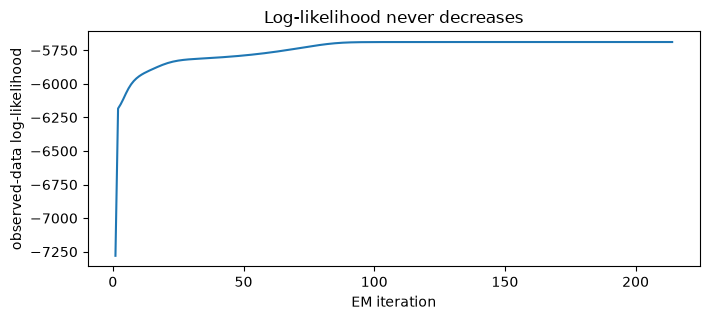

In [2]:
for log_basket in (3.0, 3.5, 4.6):
    log_prob = np.log(weight) + norm.logpdf(log_basket, mean, sd)
    responsibility = np.exp(log_prob - np.logaddexp.reduce(log_prob))
    print(
        f"log basket {log_basket:.1f} (about ${np.exp(log_basket):.0f}):",
        np.round(responsibility[order], 3),
    )

sklearn_gmm = GaussianMixture(3, n_init=5, random_state=0).fit(basket[:, None])
sklearn_order = np.argsort(sklearn_gmm.means_.ravel())
print("sklearn weights:", np.round(sklearn_gmm.weights_[sklearn_order], 3))
print("sklearn means:", np.round(sklearn_gmm.means_.ravel()[sklearn_order], 3))
print("sklearn sds:", np.round(np.sqrt(sklearn_gmm.covariances_.ravel()[sklearn_order]), 3))
print(
    "avg loglik/point sklearn:",
    round(float(sklearn_gmm.score(basket[:, None])), 4),
    "ours:",
    round(float(history[-1] / len(basket)), 4),
)

fig, ax = plt.subplots(figsize=(7.2, 3.3))
ax.plot(np.arange(1, len(history) + 1), history, color="C0")
ax.set_xlabel("EM iteration")
ax.set_ylabel("observed-data log-likelihood")
ax.set_title("Log-likelihood never decreases")
fig.tight_layout()
display(fig)
plt.close(fig)

## Step 3. Choose the number of segments in two dimensions

Three thousand customers. Features are log orders per year and log average order value, then standardised. Without standardising, the feature with the larger variance dominates. Fit $k = 1 \ldots 6$ with full covariance and five initialisations. Then look at responsibilities: customers whose top responsibility is below 0.8 are ambiguous and should get a blended treatment.


k  BIC  AIC


1 14919.3 14889.2


2 13546.0 13479.9


3 13171.5 13069.3


4 13225.6 13087.4


5 13270.2 13096.0


6 13317.9 13107.7


ambiguous share (max responsibility < 0.8): 0.056
first 3 rows of predict_proba:
[[0.84  0.16  0.001]
 [0.    1.    0.   ]
 [0.    0.    1.   ]]
weights: [0.291 0.552 0.157]
means (standardised): [[ 0.639  0.076]
 [-0.779 -0.572]
 [ 1.557  1.873]]


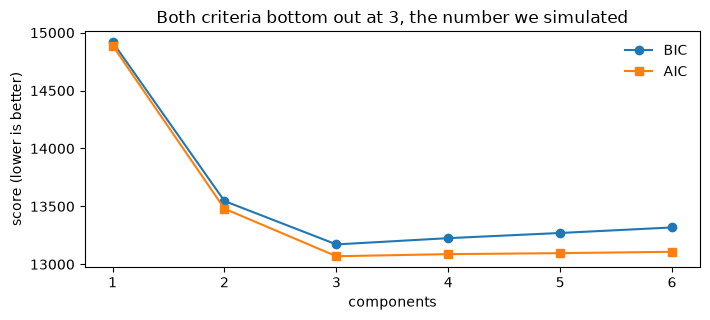

In [3]:
n_customers = 3000
segment = rng.choice(3, n_customers, p=[0.55, 0.30, 0.15])
frequency = rng.normal(np.array([1.0, 2.2, 3.0])[segment], 0.35)
order_value = rng.normal(np.array([3.2, 3.6, 4.6])[segment], 0.3)
features = StandardScaler().fit_transform(np.column_stack([frequency, order_value]))
print("k  BIC  AIC")
bic = []
aic = []
for k in range(1, 7):
    mixture = GaussianMixture(k, covariance_type="full", n_init=5, random_state=0).fit(features)
    bic.append(float(mixture.bic(features)))
    aic.append(float(mixture.aic(features)))
    print(k, round(bic[-1], 1), round(aic[-1], 1))

chosen = GaussianMixture(3, n_init=5, random_state=0).fit(features)
responsibility = chosen.predict_proba(features)
ambiguous = float(np.mean(responsibility.max(1) < 0.8))
print("ambiguous share (max responsibility < 0.8):", round(ambiguous, 3))
print("first 3 rows of predict_proba:")
print(np.round(responsibility[:3], 3))
print("weights:", np.round(chosen.weights_, 3))
print("means (standardised):", np.round(chosen.means_, 3))
assert int(np.argmin(bic)) + 1 == 3
assert int(np.argmin(aic)) + 1 == 3

fig, ax = plt.subplots(figsize=(7.2, 3.3))
ks = np.arange(1, 7)
ax.plot(ks, bic, "o-", label="BIC")
ax.plot(ks, aic, "s-", label="AIC")
ax.set_xlabel("components")
ax.set_ylabel("score (lower is better)")
ax.set_title("Both criteria bottom out at 3, the number we simulated")
ax.legend(frameon=False)
fig.tight_layout()
display(fig)
plt.close(fig)

## How to read the outputs

- Monotonic log-likelihood is the correctness check for any EM implementation.
- Weights, means, and standard deviations should land close to the simulation truth, and scikit-learn should agree on the average log-likelihood.
- A responsibility row sums to 1. A value like `[0.67, 0.33, 0.00]` is a customer between two segments, not a bug.
- `weights_` is the segment size. `means_` in the two-dimensional fit is in standardised units: back-transform before you put a business label on it.
- About 5% ambiguous customers (top responsibility below 0.8) is a reason to pass probabilities downstream instead of a hard rule.
- The BIC/AIC curve flattening after the minimum means extra segments buy little likelihood. AIC's penalty is gentler, so on messier data it tends to ask for more segments.

A reference run reached the tolerance in about 200 iterations, recovered weights near 0.51 / 0.36 / 0.13 and means near 3.02 / 4.02 / 5.24, and put the two-dimensional BIC and AIC minimum at $k = 3$.

## Pitfalls

- Unscaled features: the largest-variance column dominates.
- Heavy tails in order value break the Gaussian. Log-transform first.
- A component can collapse onto a few points and the likelihood diverges. Floor the variance, or raise `reg_covar`.
- Segment ids change order between retrains. Publish stable ids by matching centroids, and put that match in the data contract.
- Choosing $k$ only by BIC when the business can act on three to five segments.
- No parameter uncertainty from EM. Bootstrap, or fit the Bayesian mixture, when a small segment drives a decision.


## How to explain this to a CTO


In [4]:
print(
    f"The purchase data supports three shopper groups. "
    f"About {1 - ambiguous:.0%} of customers clearly belong to one group. "
    f"For the other {ambiguous:.0%} we pass the probabilities to pricing and recommendations "
    "so they can blend treatments instead of flipping a customer between segments overnight."
)
print(
    "EM is how we find those groups when nobody labelled them. "
    "It is cheap to retrain on a schedule. The trade-off against the Bayesian version is that "
    "EM gives one best answer without error bars, so for a small segment we bootstrap or use the Bayesian fit."
)

The purchase data supports three shopper groups. About 94% of customers clearly belong to one group. For the other 6% we pass the probabilities to pricing and recommendations so they can blend treatments instead of flipping a customer between segments overnight.
EM is how we find those groups when nobody labelled them. It is cheap to retrain on a schedule. The trade-off against the Bayesian version is that EM gives one best answer without error bars, so for a small segment we bootstrap or use the Bayesian fit.


## Check yourself

**Walk through EM.**
Initialise weights, means, and variances. E-step: responsibilities given the current parameters. M-step: weighted means, variances, and weights. Stop when the log-likelihood gain is tiny. The likelihood never decreases. Several initialisations, because the optimum is local.

**GMM, k-means, or a Bayesian mixture?**
k-means is a hard, spherical GMM. A GMM adds soft membership, elliptical clusters, and a likelihood for BIC. A Bayesian mixture adds priors and posterior uncertainty, and can shrink unused components, at the cost of a slower fit and label switching. EM-fitted GMM is the usual production segmentation. Use the Bayesian fit when the segment is thin or the decision needs an interval.
